# Construir e inspeccionar una frontera minera factible

**Pregunta:** ¿Cómo cambian la precedencia y la capacidad de dos recursos las acciones disponibles para construir un plan?

**Nivel:** 4 : Métodos propuestos.

## Objetivos

Sigue un grafo de bloques generado con semilla desde su origen hasta las acciones admisibles y un plan revisado de forma independiente. Al terminar podrás explicar por qué la frontera de precedencia por sí sola no basta, inspeccionar por separado los dos límites de recursos y distinguir el horizonte completo de una detención anticipada deliberada. Este cuaderno ejecuta la implementación: las llamadas importan los mismos módulos del producto previstos para el ejecutor fuera de línea. Los valores generados son datos sintéticos para desarrollar el método. No son observaciones de MineLib, resultados de un modelo entrenado ni un plan operativo. La semilla, familia, orden de variables y unidades quedan visibles para reproducir cada conteo.

## Preparación

El entorno necesita NumPy y OreBlocks fijados por el repositorio, además de Matplotlib para las figuras. Este experimento no carga pesos ni ejecuta entrenamiento. La versión 0.11 del producto aporta la línea base congelada; este cuaderno aísla la mecánica aprobada para el experimento 0.12, que tendrá versión propia. Separar esas etapas evita confundir un grafo de demostración con un caso de referencia del producto. El código es determinista con una versión de generador, familia, tamaño y semilla constantes. Si falta una dependencia o archivo fuente, la ejecución debe detenerse en preparación y no sustituir la implementación silenciosamente.

Las versiones fijadas son `oreblocks==0.6.6`, `numpy==2.5.1` y `matplotlib==3.11.2`.

```bash
python -m pip install oreblocks==0.6.6 numpy==2.5.1 matplotlib==3.11.2
```

Imprime las versiones instaladas antes de importar el método.

In [1]:
# Confirm exact versions before loading product modules.
import importlib.metadata as metadata
print({name: metadata.version(name) for name in ('oreblocks', 'numpy', 'matplotlib')})

{'oreblocks': '0.6.6', 'numpy': '2.5.1', 'matplotlib': '3.11.2'}


## Datos

El grafo asigna un índice entero canónico a cada bloque, una relación acíclica de predecesores, valor económico descontado, consumo de dos recursos y capacidades por período. Las cuatro familias del generador modifican la geometría de dependencias y conservan el mismo contrato de datos. Aquí elegimos la familia de cruces, cuyos nodos pueden depender tanto de una fila previa como de un bloque vecino. La reducción de aristas usa la semilla y por ello la estructura es reproducible. Las variables de nodo tienen nombres y orden fijos: valor, tonelaje, proporción de procesamiento, ley, profundidad y grados locales del grafo. No incluyen identificadores, etiquetas de partición ni resultados.

Genera un grafo de cruces con la semilla declarada e inspecciona su recibo de origen y matriz de variables.

In [2]:
# Generate one reproducible graph and inspect its source contract.
# Locate the repository root from the notebook's working directory.
from pathlib import Path
import sys
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'data-pipeline').is_dir())
sys.path.insert(0, str(ROOT / 'data-pipeline'))
from pipeline.model.frontier_data import generate_graph, FEATURE_NAMES
SEED, FAMILY, SIZE = 4217, 'crosscut', 96
graph = generate_graph(SEED, FAMILY, SIZE, periods=8)
instance = graph.instance
print({'generator': graph.family_parameters, 'seed': graph.seed})
print({'blocks': len(instance.values), 'arcs': sum(map(len, instance.predecessors))})
print({'feature_names': FEATURE_NAMES, 'feature_shape': graph.node_features.shape})
if not np.isfinite(graph.node_features).all():
    raise ValueError('the generator emitted non-finite feature values')

{'generator': 'frontier-graphs/1.0.0:crosscut:size=96:periods=8:v1', 'seed': 4217}
{'blocks': 96, 'arcs': 180}
{'feature_names': ('value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count'), 'feature_shape': (96, 7)}


## Método

En cada estado, un bloque es elegible cuando todos sus predecesores inmediatos ya están programados en un período no posterior al actual. La máscara de recursos elimina después cualquier bloque que supere al menos un límite residual. Por tanto, un bloque listo por precedencia puede seguir siendo inadmisible por capacidad. El entorno agrega acciones explícitas para detener el período o el plan, de modo que una política pueda reservar un período o devolver un plan parcial válido. Aquí usamos una puntuación determinista y transparente solo para observar las transiciones. No es una política aprendida y su salida no se describe como resultado de entrenamiento ni de evaluación.

En el período \(t\), el bloque \(b\) está listo por precedencia solo si no está asignado y todos sus predecesores ya fueron asignados a un período no posterior a \(t\). Sea \(P_b\) el conjunto de predecesores y \(A_t\) las asignaciones al período \(t\).

$$
E_t=\{b\notin A \colon P_b\subseteq\{i:p_i\leq t\}\}.
$$

$$
F_t=\{b\in E_t \colon r_{bk}\leq C_{tk}-\sum_{i\in A_t}r_{ik}\;\forall k\}.
$$

El primer conjunto impone el orden del grafo; el segundo verifica el vector completo de recursos frente a la capacidad restante. Un bloque fuera de \(F_t\) puede seguir siendo útil más adelante, por lo que excluirlo del conjunto actual no lo elimina de la instancia. `stop-period` avanza el reloj sin asignar otro bloque y `stop-schedule` devuelve el plan parcial factible actual. Estas acciones explícitas muestran capacidad no usada y cobertura incompleta en lugar de ocultarlas con una asignación inválida.

Importa las funciones del producto y compara la elegibilidad por precedencia con ambos límites de recursos.

In [3]:
# Import the product frontier and validator functions.
from pipeline.model.frontier_policy import (
    feasible_frontier, precedence_frontier, replay_frontier_policy, validate_schedule,
)
ready = precedence_frontier(instance, (), 0)
feasible = feasible_frontier(instance, (), 0)
print({'period': 0, 'precedence_ready': len(ready)})
print({'resource_feasible': len(feasible), 'removed_by_capacity': len(ready) - len(feasible)})
print({'ready_indices': ready[:12], 'feasible_indices': feasible[:12]})

{'period': 0, 'precedence_ready': 1}
{'resource_feasible': 1, 'removed_by_capacity': 0}
{'ready_indices': (0,), 'feasible_indices': (0,)}


Reproduce una puntuación transparente para mostrar estados sucesivos. Es un ejemplo mecánico, no un resultado aprendido.

In [4]:
# Replay value per mining unit as an illustrative deterministic score.
def illustrative_score(block, period, assigned):
    if block < 0:
        return -1e6
    return float(instance.values[block] / max(instance.resources[block, 0], 1e-12))

result = replay_frontier_policy(instance, illustrative_score, tonnage=graph.tonnage)
ready_counts, feasible_counts, prefix = [], [], []
for assignment in result.assignments:
    ready_counts.append(len(precedence_frontier(instance, prefix, assignment.period)))
    feasible_counts.append(len(feasible_frontier(instance, prefix, assignment.period)))
    prefix.append(assignment)
print({'assignments': len(result.assignments), 'stopped': result.stopped})
print({'npv': round(result.npv, 4), 'tonnage_coverage': round(result.tonnage_coverage, 4)})
print({'positive_value_coverage': round(result.positive_value_coverage, 4)})

{'assignments': 87, 'stopped': 'horizon-complete'}
{'npv': -62.1729, 'tonnage_coverage': 0.9134}
{'positive_value_coverage': 0.8055}


Recalcula el objetivo desde la instancia original y verifica cada bloque elegido contra su frontera factible anterior.

In [5]:
# Independently recompute the exported objective from source arrays.
independent_npv = validate_schedule(instance, result.assignments)
print({'independent_npv': round(independent_npv, 4)})
print({'objective_matches': bool(np.isclose(independent_npv, result.npv))})

{'independent_npv': -62.1729}
{'objective_matches': True}


Verifica cada asignación contra su máscara previa; así se revisan las transiciones, no solo los totales finales.

In [6]:
# Rebuild each prefix and prove every selected block was admissible.
prefix = []
admissible = []
for assignment in result.assignments:
    admissible.append(assignment.block in feasible_frontier(instance, prefix, assignment.period))
    prefix.append(assignment)
print({'admissible_assignments': sum(admissible), 'schedule_assignments': len(result.assignments)})

{'admissible_assignments': 87, 'schedule_assignments': 87}


## Comparación

La primera figura compara la cantidad de bloques listos por precedencia con la cantidad menor que además cabe en los recursos al inicio de cada período. Una diferencia significa que la capacidad, y no la precedencia, eliminó opciones. La segunda figura muestra los valores de los bloques seleccionados y el uso de recursos del plan por período. Las vistas responden preguntas distintas: una diagnostica la máscara de acciones y la otra revisa cómo las decisiones consumen el presupuesto declarado. Se calculan desde la instancia generada y el plan validado; ningún dato se copió de un manuscrito ni se escribió a mano en una gráfica.

Grafica las opciones listas por precedencia y factibles por recursos en cada decisión.

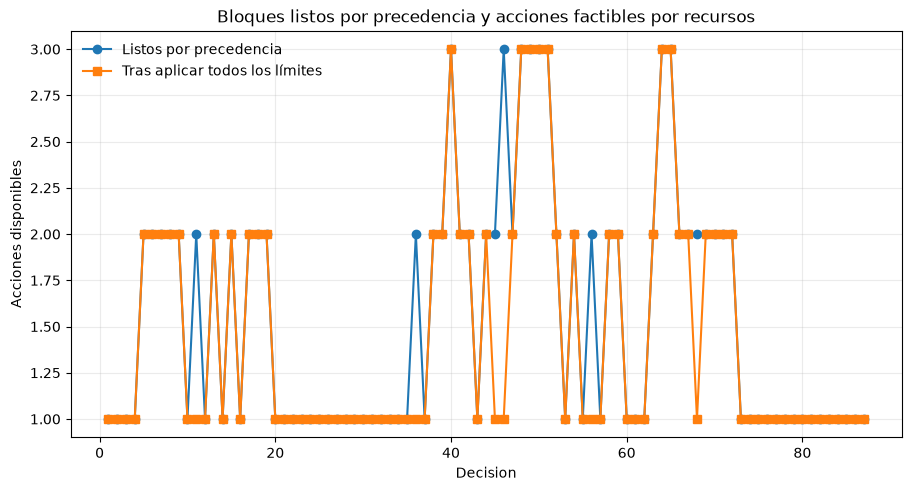

In [7]:
# Plot the number of eligible actions before and after resource filtering.
fig, ax = plt.subplots(figsize=(9, 4.8), constrained_layout=True)
decisions = np.arange(1, len(ready_counts) + 1)
ax.plot(decisions, ready_counts, marker='o', label='Listos por precedencia')
ax.plot(decisions, feasible_counts, marker='s', label='Tras aplicar todos los límites')
ax.set_title('Bloques listos por precedencia y acciones factibles por recursos')
ax.set_xlabel('Decision')
ax.set_ylabel('Acciones disponibles')
ax.grid(alpha=.25)
ax.legend(frameon=False)
plt.show()

## Evidencia

La evidencia tiene límites explícitos. Informamos el recibo del generador, forma de variables, conteos de frontera, longitud del plan, objetivo recalculado por el validador independiente, cobertura de tonelaje, cobertura de valor y motivo de detención. El validador vuelve a comprobar unicidad, precedencia, capacidad por período y objetivo descontado desde las asignaciones exportadas. Superar esa comprobación establece la factibilidad de este único plan generado. No mide generalización, no compara con otro método de planificación, no establece beneficios ni evalúa los trece casos del producto. Esas preguntas requieren el protocolo de prueba congelado y un rebake completo.

Compara los valores firmados con el uso minero y su límite por período; los ejes usan unidades distintas.

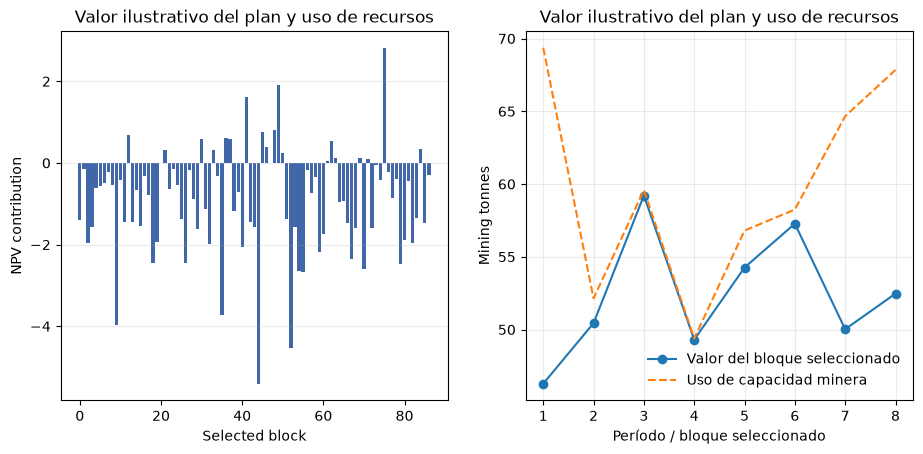

{'mining_use_by_period': [46.28, 50.44, 59.21, 49.3, 54.26, 57.27, 50.02, 52.47]}
{'mining_limit_by_period': [69.37, 52.15, 59.58, 49.38, 56.8, 58.25, 64.66, 67.84]}


In [8]:
# Compare signed selected values with mining use and the declared limits.
period_use = np.zeros((len(instance.capacities), instance.resources.shape[1]))
for assignment in result.assignments:
    period_use[assignment.period] += instance.resources[assignment.block]
selected_values = [instance.values[a.block] for a in result.assignments]
fig, (value_ax, resource_ax) = plt.subplots(1, 2, figsize=(11, 4.8))
value_ax.bar(np.arange(len(selected_values)), selected_values, color='#4267a9')
value_ax.set_title('Valor ilustrativo del plan y uso de recursos')
value_ax.set_xlabel('Selected block')
value_ax.set_ylabel('NPV contribution')
periods = np.arange(1, len(instance.capacities) + 1)
resource_ax.plot(periods, period_use[:, 0], marker='o', label='Valor del bloque seleccionado')
resource_ax.plot(periods, instance.capacities[:, 0], linestyle='--', label='Uso de capacidad minera')
resource_ax.set_title('Valor ilustrativo del plan y uso de recursos')
resource_ax.set_xlabel('Período / bloque seleccionado')
resource_ax.set_ylabel('Mining tonnes')
resource_ax.grid(alpha=.25)
resource_ax.legend(frameon=False)
value_ax.grid(axis='y', alpha=.25)
plt.show()
print(dict(mining_use_by_period=np.round(period_use[:, 0], 2).tolist()))
print(dict(mining_limit_by_period=np.round(instance.capacities[:, 0], 2).tolist()))

La máscara elimina un bloque solo después de revisar cada dimensión de recursos. Si las curvas difieren, inspecciona la capacidad residual antes de atribuirlo a la estructura del grafo. Esta figura diagnostica un estado, no compara desempeño. La validación siguiente corresponde únicamente a este plan y esta semilla; no estima el desempeño en grafos desconocidos.

### Sensibilidad y límites

Variamos todas las capacidades por período con el mismo multiplicador y mantenemos fijo el grafo generado, sus valores, recursos y aristas de precedencia. El conjunto listo por precedencia en el período cero no debería cambiar porque el orden del grafo no depende de capacidad. El conjunto factible puede reducirse al ajustar los límites y coincidir con el conjunto listo cuando todos los bloques elegibles caben. Esta diferencia comprueba el mecanismo que usará una política futura, no la calidad de una puntuación aprendida.

El barrido usa 0.65, 0.82 y 1.00 veces el vector de capacidades declarado. No es un análisis de sensibilidad de capacidad minera en unidades físicas: el generador tiene dos dimensiones de recursos y valores sintéticos. Una acción bloqueada puede reconsiderarse en un período posterior; si la capacidad total del horizonte es insuficiente, el plan puede quedar parcial. Por eso las fracciones de cobertura acompañan al objetivo. El validador explícito sigue siendo necesario tras la reproducción, pues una máscara correcta en cada paso no prueba que la lista exportada no haya sido alterada u ordenada nuevamente.

escala=0.65: listas=1; factibles=1
escala=0.82: listas=1; factibles=1
escala=1.00: listas=1; factibles=1


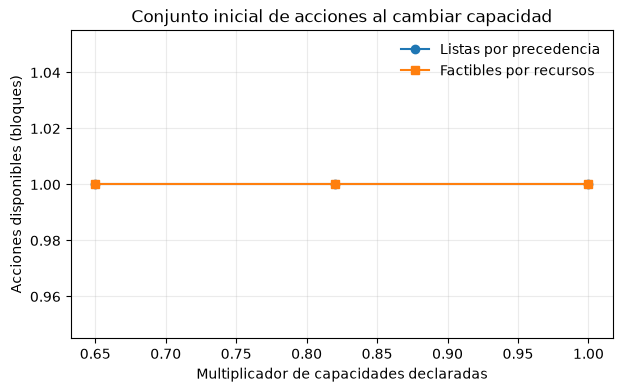

In [9]:
# Comparar acciones listas y factibles bajo escalas comunes de capacidad.
from dataclasses import replace
escalas_capacidad = [0.65, 0.82, 1.00]
listas_por_escala, factibles_por_escala = [], []
for escala in escalas_capacidad:
    instancia_escalada = replace(instance, capacities=instance.capacities * escala)
    listas_por_escala.append(len(precedence_frontier(instancia_escalada, (), 0)))
    factibles_por_escala.append(len(feasible_frontier(instancia_escalada, (), 0)))
    print(f'escala={escala:.2f}: listas={listas_por_escala[-1]}; '
          f'factibles={factibles_por_escala[-1]}')
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(escalas_capacidad, listas_por_escala, marker='o', label='Listas por precedencia')
ax.plot(escalas_capacidad, factibles_por_escala, marker='s', label='Factibles por recursos')
ax.set(title='Conjunto inicial de acciones al cambiar capacidad',
       xlabel='Multiplicador de capacidades declaradas', ylabel='Acciones disponibles (bloques)')
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.show()

Las curvas separan elegibilidad estructural del filtro de recursos. La cantidad lista permanece constante porque el grafo no cambia; las acciones factibles responden a ambas dimensiones de capacidad. Si un período no ofrece bloques factibles, una acción explícita de detención puede avanzar a uno posterior. La figura no muestra entrenamiento, transferencia entre familias ni calidad del objetivo, y una frontera factible más grande no implica automáticamente una mejor decisión.

### Usa el contrato de frontera con tus propios datos

Crea una `FrontierInstance` con orden estable de bloques. El vector de valor tiene un valor finito por bloque; `resources` es una matriz bloque-por-recurso con consumos no negativos; `predecessors` contiene los índices inmediatos requeridos; `capacities` es período-por-recurso; y `discount_rate` define el objetivo. Confirma que los índices van del prerrequisito al bloque dependiente y que el grafo es acíclico. Cada columna de recursos debe usar la misma unidad en consumo y capacidad. Mantén tonelaje por separado si informarás cobertura de tonelaje; el consumo de recursos no equivale necesariamente a tonelaje.

En cada decisión, entrega asignaciones existentes y período a `precedence_frontier` y `feasible_frontier`. El segundo resultado es un subconjunto admisible, no un ranking. Una puntuación de política puede ordenar solo las acciones de bloque devueltas y las acciones explícitas de detención. Reproduce la secuencia elegida en el entorno del producto, exporta las asignaciones y llama `validate_schedule` contra la instancia original. Revisa el valor descontado recomputado y ambas coberturas; conserva motivo de detención y conteos de acciones rechazadas. No uses la propia máscara de la política como validador de exportación.

Para modelos de bloques sin procesar, conserva IDs fuente aparte de índices canónicos y genera un mapeo reversible. Registra filas filtradas y sus motivos. Si un campo fuente no existe, rechaza o adapta explícitamente el contrato; nunca completes ley o un recurso con una constante silenciosamente. El grafo crosscut generado solo muestra la interfaz. Una política de producción también necesita normalizador congelado solo con entrenamiento, particiones separadas por familia, procedencia del checkpoint y evaluación independiente reservada.

La familia crosscut del generador tiene dos tipos de aristas entrantes: una dependencia por fila y otra lateral. Así se ve que la elegibilidad es una propiedad del grafo y no una ordenación simple de coordenadas. El filtro de capacidad es independiente: consulta el vector completo de recursos, incluida la dimensión de procesamiento, antes de exponer una acción. Cambiar la puntuación de la reproducción no puede saltarse el filtro porque el entorno elige solo entre acciones admisibles. Esta interfaz permite integrar una política aprendida, pero esta lección de mecánica no la entrena ni la valida.

Una revisión útil también pregunta si una acción fue excluida por el motivo correcto. En cada paso, compara la lista de asignaciones, el vector de recursos restantes y los períodos de predecesores con los candidatos de ambas funciones de frontera. Si un candidato desaparece solo tras el filtro de recursos, identifica el recurso vinculante; si antes no está disponible, inspecciona sus predecesores. Esta comprobación manual de estados seleccionados complementa el validador independiente y ayuda a depurar errores de contrato sin tratar toda frontera vacía como falla del solver.

## Resultados

Interpreta juntos la tabla impresa y los gráficos. Un conteo bajo de acciones factibles no es por sí mismo un defecto de la política: puede ser consecuencia correcta de un recurso vinculante. Un plan parcial puede ser factible y dejar tonelaje o bloques de valor positivo sin extraer; por eso se informan ambas coberturas en unidades separadas. La puntuación de demostración favorece valor positivo por unidad de capacidad minera, pero es intencionalmente simple y no afirma optimizar el objetivo multiperíodo. Lee la salida como un ejemplo trabajado del flujo de datos y del validador, no como evidencia de que una puntuación sea preferible. **Respuesta:** En este ejemplo de 96 bloques, la precedencia y la capacidad forman conjuntos de acciones distintos, y la comprobación independiente confirma el objetivo exportado.

## Resumen

Trazaste un grafo con semilla hasta la máscara, avanzaste períodos mediante acciones explícitas y verificaste las asignaciones finales de manera independiente. La invariancia central es validar el plan exportado desde la instancia original, en vez de confiar en que el entorno expuso antes una máscara. Antes de integrar el entrenamiento, el contrato sumará normalización exclusiva de entrenamiento, recibo de particiones disjuntas, hash del checkpoint y presupuesto por integrante. La aplicación leerá trazas confirmadas; el navegador no ejecutará PPO ni cargará pesos de entrenamiento. El siguiente cuaderno de investigación revisará el recibo congelado y la evaluación reservada cuando esos artefactos existan. El ejemplo es lo bastante pequeño para auditar cada bloque, pero las mismas comprobaciones independientes rigen los tamaños sintéticos declarados. Un ejemplo exitoso verifica software, no constituye evidencia estadística. Al adaptar el flujo, congela primero el contrato de datos, ejecuta después el experimento reservado y finalmente informa cada caso fallido, parcial y completo sin filtrar resultados.

## Referencias

El patrón de política sobre grafos toma contexto de la investigación de programación de proyectos con recursos restringidos, donde una política ordena tareas elegibles y un procedimiento de generación mantiene la factibilidad. El límite de transferencia importa: esos trabajos optimizan objetivos distintos y no demuestran desempeño de PhaseFlow. La fuente siguiente aporta contexto metodológico. La implementación mostrada es el diseño aprobado para PhaseFlow que continúa en desarrollo, y cada valor numérico del cuaderno se genera con la semilla sintética declarada en vez de extraerse de la publicación.

[Teichteil-Königsbuch et al., ICAPS 2023](https://doi.org/10.1609/icaps.v33i1.27244).
- Resource-constrained scheduling policy with graph neural networks, ICAPS 2023: https://doi.org/10.1609/icaps.v33i1.27244
- OreBlocks scheduling package: https://pypi.org/project/oreblocks/
- MineLib open-pit scheduling problem library: https://doi.org/10.1007/s10479-012-1258-3

Huang y Ontañón (2022) muestran que una máscara de acciones dependiente del estado puede definir una distribución válida para el gradiente de política, y estudian el enmascaramiento en μRTS; sus resultados justifican estudiar el muestreo enmascarado, pero no demuestran factibilidad ni desempeño en planificación minera a cielo abierto.

- Huang, S., & Ontañón, S. (2022). A closer look at invalid action masking in policy gradient algorithms. The International FLAIRS Conference Proceedings, 35. https://doi.org/10.32473/flairs.v35i.130584
